In [1]:
import os
import scanpy as sc
import matplotlib.pyplot as plt

In [2]:
pth = os.path.join('..', '..')
pth_in = os.path.join(pth, 'data', 'cancer', 'invertebrate', 'drosophila')
pth_out = os.path.join(pth, 'figures', 'invertebrate', 'drosophila')

In [3]:
adata = sc.read_h5ad(os.path.join(pth_in, 'follicle.h5ad'))
adata

AnnData object with n_obs × n_vars = 13429 × 13948
    obs: 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'n_genes', 'n_counts', 'leiden', 'celltype'
    var: 'Accession', 'Chromosome', 'End', 'Start', 'Strand', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'celltype_colors', 'diffmap_evals', 'hvg', 'leiden', 'leiden_colors', 'log1p', 'neighbors', 'pca', 'umap'
    obsm: 'X_diffmap', 'X_pca', 'X_umap'
    varm: 'PCs'
    layers: 'ambiguous', 'matrix', 'spliced', 'unspliced'
    obsp: 'connectivities', 'distances'

In [4]:
ix = ['Mitotic',
      'Postmitotic',
      'Main Body',
      'Posterior',
      'Terminal',
      'Stretched',
      'Border',
      'Stalk']

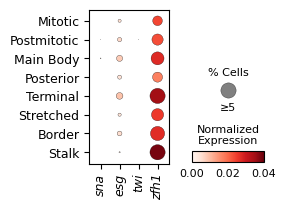

In [16]:
g_plt = ['sna', 'esg', 'twi', 'zfh1']

# expression dotplot
fs1, fs2 = 9, 8
dp = sc.pl.dotplot(adata, g_plt, 'celltype',
                   categories_order = ix,
                   dot_max = .05,
                   vmin = 0, vmax = .04,
                   figsize = (2.1, 2),
                   return_fig = True,
                   show = False)

dp.style(largest_dot = 120,
         x_padding = .6,
         y_padding = .6)
dp.legend(width = .9)

ax = dp.get_axes()
ax_main = ax['mainplot_ax']
ax_size = ax['size_legend_ax']
cax = ax['color_legend_ax']

ax_size.set_title('% Cells', size = fs2, pad = -9)
ax_size.tick_params('x', size = 0, labelsize = fs2, pad = 2.5)
ax_size.set_xticklabels(['≥5'])
cax.set_title('Normalized\nExpression', size = fs2, pad = 5.5)
cax.tick_params('x', size = 0, labelsize = fs2, pad = 5)

xlim = ax_size.get_xlim()
xlim = (xlim[0] - .66, xlim[1] + .33)
ax_size.set_xlim(xlim)

pos_main = ax_main.get_position()
pos_size = ax_size.get_position()
pos_color = cax.get_position()

ax_size.set_position([pos_size.x0,
                      pos_size.y0,
                      1.2 * pos_size.width,
                      pos_size.height])

cax.set_position([pos_color.x0,
                  pos_color.y0 + .01 * pos_main.height,
                  1.2 * pos_color.width,
                  pos_color.height])

ax_main.set_xticklabels(ax_main.get_xticklabels(),
                        fontsize = fs1,
                        fontstyle = 'italic')
ax_main.tick_params('y', labelsize = fs1)

fn = os.path.join(pth_out, 'expression.pdf')
plt.savefig(fn, bbox_inches = 'tight')